## CS328 Assignment 3: Exercise Recognition and Rep Counting

The objective of this assignment is to build a complete pipeline for exercise recognition from phone accelerometer data. Fitness trackers and gym apps do this every day: they find when you are exercising, recognize the exercise, and count your reps. In this assignment, you will be working with the accelerometer data the class collected with Sensor Logger in the Exercises Study. Each recording is one set of one of eight exercises: squats, jumping jacks, push-ups, sit-ups, ab crunches, lunges, bicep curls, and lat raises.

You will get hands-on experience in several key aspects of mobile health sensing:
1. **Segmentation**: finding the exercise set inside a recording, and ignoring the rest and the phone handling at the start and the end.
2. **Rep counting**: turning the set into a number of reps with peak detection, on the right signal.
3. **Classification**: windowing, feature extraction, and model training, and combining the window predictions into one label per recording.
4. **Error analysis**: finding out which step of the pipeline caused each error.

Unlike A2, where every second of a recording was the same activity, an exercise recording has a beginning, an end, and separate reps in between. Errors also compound: if the segmentation keeps the phone handling, the rep counter counts it as reps, and the classifier sees windows that are not the exercise.

#### Imports Block

Make sure all imports are in this block below.

In [35]:
# -- IMPORTS START --
import pandas as pd
import glob
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree, metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from util import (viz_tree, load_manifest, split_recordings, load_recording, prepare_recording,
                  calc_magnitude, remove_noise, add_features, baseline_features, no_segment,
                  baseline_segment, cut_segment, baseline_count_reps, build_feature_frames,
                  select_recordings, evaluate_rep_counter, rep_metrics, plot_segment)
# -- IMPORTS END --

# enable zooming into graphs
%matplotlib inline
plt.rcParams['figure.figsize'] = [9, 6] # width, height in inches

#### About the data (read this before you start)

- **`data/manifest.csv`** has one row per recording: `path` (e.g., `data/squats/001_2026-09-10_01-40-18.csv`, a number and the date and time of the recording), `exercise`, `reps` (the number of reps the student counted), and `placement` (Hand, Trouser, Jacket, Armband, Bag/backpack).
- Each CSV is the Sensor Logger `Accelerometer` sensor: **linear acceleration in m/s² with gravity removed** (as in A2). `load_recording` returns `time` in seconds from the start of the recording, and the `x`, `y`, `z` axes.
- Most phones log at ~100 Hz, but a few recordings are at 50-60 Hz. Use the `sample_rate` that `load_recording` returns instead of hard-coding it.
- The protocol was: stand still ~5 s → do the set → stand still ~5 s → Stop. **Not everyone did this.** Many recordings start and end with phone handling (putting the phone in a pocket, taking it out to tap Stop), which looks like a short burst of large motion.
- **Placement matters.** With the phone in a trouser pocket, upper-body exercises (bicep curls, lat raises) barely move the phone, and some recordings are almost flat.
- **Reps are self-reported.** Most are right, but some may be off by a rep or two.
- **Some classes are small**: lat raises has 19 recordings and ab crunches 28, while squats has 106.

**Hint (why the magnitude is not enough for counting):** in a squat, going down and coming up both accelerate the phone, so the magnitude often has two peaks per rep. One axis (or the direction that moves the most) has one cycle per rep.

#### Helper functions (provided in util.py, do not modify)

| Function | What it does |
|-|-|
| `load_manifest(root)` | Reads `data/manifest.csv` |
| `split_recordings(manifest, test_size, random_state)` | Splits **recordings** (not windows) into two parts, with the same mix of exercises in both |
| `prepare_recording(path)` | `load_recording` → `calc_magnitude` → `remove_noise`. Returns `data` (columns `time`, `x`, `y`, `z`, `accel_mag`, `filtered_accel_mag`) and `sample_rate` |
| `no_segment(data, sample_rate)` | The whole recording, as `(start_sec, end_sec)` |
| `baseline_segment(data, sample_rate)` | Baseline segmentation: active where the 1 s moving std of `filtered_accel_mag` is above 0.5 m/s². Returns `(start_sec, end_sec)` from the first to the last active sample |
| `cut_segment(data, start_sec, end_sec)` | Keeps only the samples inside the segment |
| `baseline_count_reps(data, sample_rate, exercise)` | Baseline rep counter (A1-style): peaks of `filtered_accel_mag` above its mean, at least 1 s apart |
| `baseline_features(window, sample_rate)` | The 7 A2 baseline features (`add_features`) |
| `build_feature_frames(manifest, window_sec, segment_fn, feature_fn)` | For every recording: `prepare_recording` → `segment_fn` → `cut_segment` → windows of `window_sec` with 50% overlap → `feature_fn`. One row per window, plus the `exercise` and `recording` columns |
| `select_recordings(frames, manifest)` | Keeps only the windows of the recordings in `manifest` |
| `evaluate_rep_counter(manifest, segment_fn, count_fn)` | Runs `segment_fn` and `count_fn` on every recording. One row per recording with `true_reps`, `pred_reps`, and `error` (= pred − true) |
| `rep_metrics(results, by=None)` | `MAE` (mean absolute error in reps), `within_2` (share of recordings within ±2 reps), `bias` (above 0 = counting too many). Use `by='exercise'` or `by='placement'` for a breakdown |
| `plot_segment(data, segments, title)` | Plots `filtered_accel_mag` with one shaded span per segmentation, e.g. `{'baseline': (start_sec, end_sec)}` |

#### Train / validation / test split (provided)

Everyone uses the same split. **Train** recordings (70%) are split again into **fit** and **validation** recordings. Use fit and validation to choose your segmentation, window length, features, hyperparameters, and rep-counting settings. Use the **test** recordings only for the final numbers in the tables. Never pick a setting because it looks better on test.

**Note:** the validation set is small (76 recordings). With a different `random_state` in the split, the same model can score several points higher or lower, so a difference of a few points between two settings may just be noise. Only trust clear differences.

In [36]:
manifest = load_manifest('./data')
train_manifest, test_manifest = split_recordings(manifest, test_size=0.3, random_state=42)
fit_manifest, val_manifest = split_recordings(train_manifest, test_size=0.25, random_state=42)

print('train:', len(train_manifest), '| test:', len(test_manifest),
      '| fit:', len(fit_manifest), '| validation:', len(val_manifest))
manifest.groupby('exercise').size()

train: 301 | test: 129 | fit: 225 | validation: 76


exercise
Ab crunches       28
Bicep curls       50
Jumping jacks     87
Lat raises        19
Lunges            42
Push-ups          58
Sit-ups           40
Squats           106
dtype: int64

Jumping jacks | placement: Hand | reps: 24 | sample rate: 100 Hz


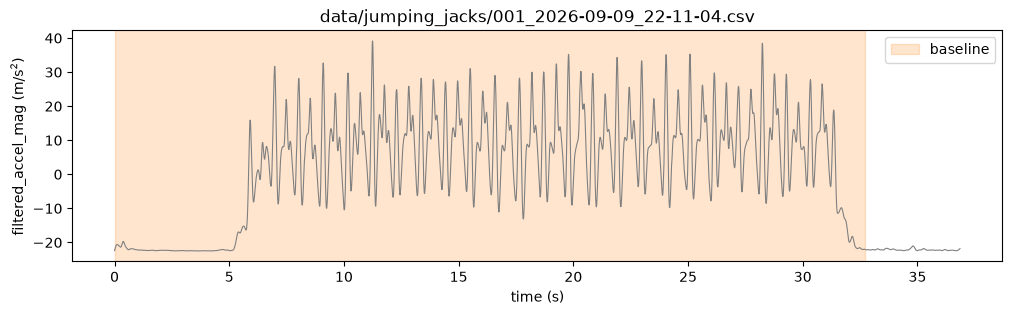

In [37]:
# Example: one recording with the baseline segmentation
row = manifest.iloc[0]
data, sample_rate = prepare_recording(row['path'])
print(row['exercise'], '| placement:', row['placement'], '| reps:', row['reps'], '| sample rate: %.0f Hz' % sample_rate)
plot_segment(data, {'baseline': baseline_segment(data, sample_rate)}, title=row['path'])

###  Assignment: Function 1: find_exercise_segment(data, sample_rate)

**Instructions:**
Define the `find_exercise_segment` function that finds the exercise set inside one recording. This is the **segmentation** axis in RUBRIC.md (exploration report §1).

- The function takes as arguments:
  - `data`: a DataFrame with the columns `time` (seconds), `x`, `y`, `z`, `accel_mag`, and `filtered_accel_mag` (from `prepare_recording`)
  - `sample_rate`: the sampling frequency of the recording
- The function returns `(start_sec, end_sec)`: the start and the end of the set, in seconds.

**Hints and Instructions:**
- As provided, the function returns the baseline segmentation, so you can run the whole notebook before writing it. Look at the plots: the baseline often keeps the phone handling at both ends, because a fixed threshold of 0.5 m/s² is easy to cross.
- Ideas to try:
  - **Protocol-based**: the protocol asks for ~5 s of standing still at both ends, so drop the first and the last few seconds. Simple, but it cuts reps when someone did not stand still.
  - **Adaptive threshold**: set the threshold from the recording itself, e.g., between its quiet level (a low percentile of the moving std) and its active level (a high percentile), instead of a fixed 0.5 m/s².
  - **Ignore short bursts**: phone handling lasts 1-2 s, while a set lasts much longer. Drop active parts shorter than a few seconds, or keep only the longest one.
  - **Use the rep band**: reps are slow (one every 1-4 s), while handling is short and sharp. Band-pass the signal to ~0.2-1.5 Hz before measuring the energy.
- Compare the baseline with **at least one approach of your own** (exploration report §1). Write each approach as its own function with the same two arguments, so you can pass it to `evaluate_rep_counter` and `build_feature_frames`. Keep the best one as `find_exercise_segment`. You will measure the effect of segmentation in the rep counting and classification sections.

In [38]:
def find_exercise_segment(data, sample_rate):
    """
    Adaptive segmentation:
    1. Computes moving standard deviation of filtered acceleration magnitude over 1 s.
    2. Determines an adaptive threshold between quiet (15th percentile) and active (85th percentile):
       threshold = max(quiet + 0.25 * (active - quiet), 0.08).
    3. Bridges brief pauses between reps (< 2 s) using rolling maximum.
    4. Drops short bursts (< 3 s) typically caused by phone handling (putting in pocket / tapping stop).
    5. Returns the longest retained segment. Near-flat recordings use the whole
       recording; if no interval survives, falls back to baseline_segment.
    """
    if len(data) < 2:
        return float(data['time'].iloc[0]), float(data['time'].iloc[-1])

    win = max(int(sample_rate), 2)
    sig = data['filtered_accel_mag'] if 'filtered_accel_mag' in data else data['accel_mag']
    moving_std = sig.rolling(win, center=True, min_periods=1).std()

    q_quiet = moving_std.quantile(0.15)
    q_active = moving_std.quantile(0.85)

    # Flat or near-motionless recording fallback
    if (q_active - q_quiet) < 0.05:
        return float(data['time'].iloc[0]), float(data['time'].iloc[-1])

    # Adaptive threshold: 25% between quiet and active level (min 0.08 m/s^2)
    threshold = max(q_quiet + 0.25 * (q_active - q_quiet), 0.08)

    is_active = (moving_std > threshold)

    # Bridge brief pauses (< 2.0 s) between consecutive reps
    bridge_win = max(int(2.0 * sample_rate), 1)
    smooth_active = is_active.rolling(bridge_win, center=True, min_periods=1).max().fillna(0).astype(bool)

    # Detect contiguous active regions
    diff = smooth_active.astype(int).diff().fillna(0)
    starts = data['time'][diff == 1].tolist()
    ends = data['time'][diff == -1].tolist()
    if smooth_active.iloc[0]:
        starts.insert(0, data['time'].iloc[0])
    if smooth_active.iloc[-1]:
        ends.append(data['time'].iloc[-1])

    segments = []
    for s, e in zip(starts, ends):
        active_times = data['time'][(data['time'] >= s) & (data['time'] <= e) & is_active]
        if len(active_times) > 0:
            act_s, act_e = active_times.iloc[0], active_times.iloc[-1]
            if (act_e - act_s) >= 3.0:  # Drop bursts < 3 s (phone handling)
                segments.append((act_s, act_e, act_e - act_s))

    if not segments:
        return baseline_segment(data, sample_rate)

    # Select the primary (longest) exercise segment
    segments.sort(key=lambda x: x[2], reverse=True)
    best_start, best_end, _ = segments[0]

    return float(best_start), float(best_end)

def protocol_segment(data, sample_rate):
    """Trim the protocol's first and last 5 seconds; retain short recordings."""
    start, end = float(data['time'].iloc[0]), float(data['time'].iloc[-1])
    if end - start <= 11.0:
        return start, end
    return start + 5.0, end - 5.0


## Assignment-Segmentation: Visual Check

1. **Plot** at least **6 recordings** from `fit_manifest` with different exercises and placements, with the baseline and your segmentation, e.g. `plot_segment(data, {'baseline': ..., 'yours': ...})`.

2. **Find** one recording where the baseline fails and one where your method fails. Use them in §1 of your exploration report.

3. **Interpretation of the results**: What does the baseline get wrong? What does your method fix, and where does it still break?

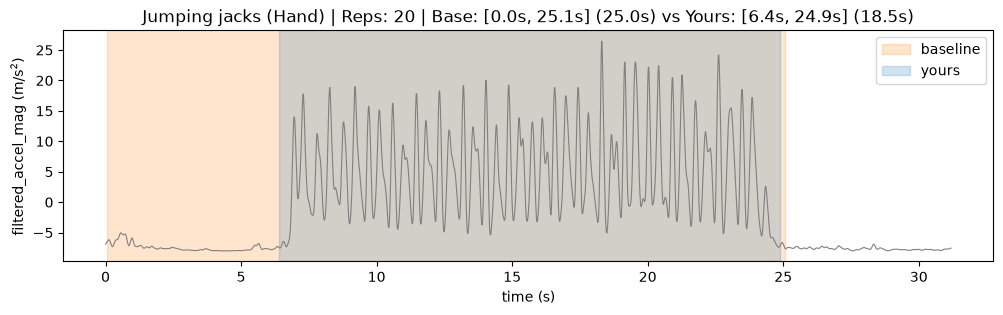

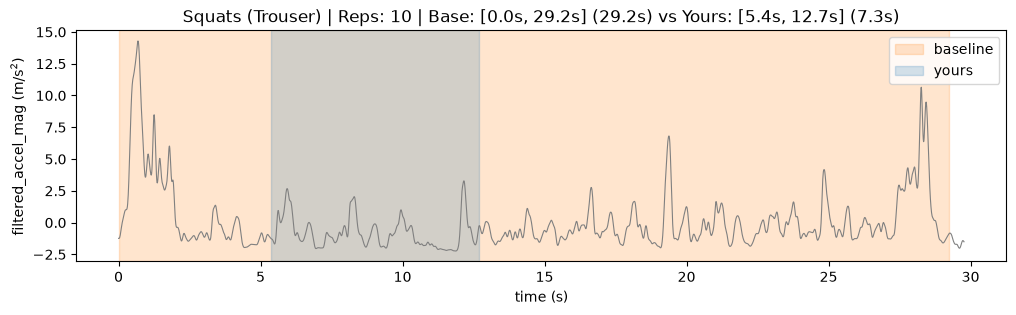

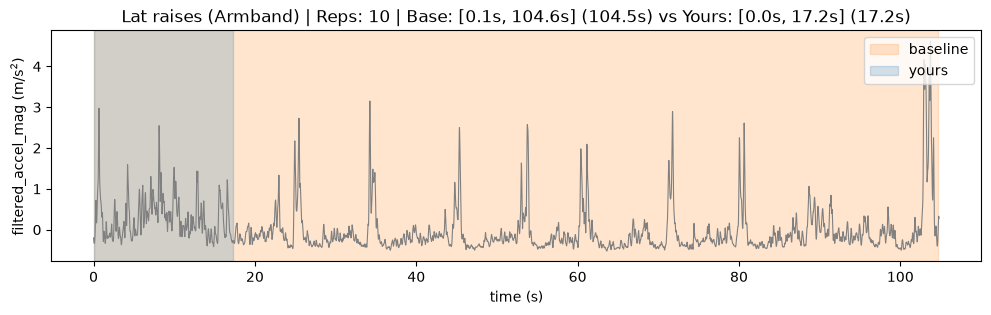

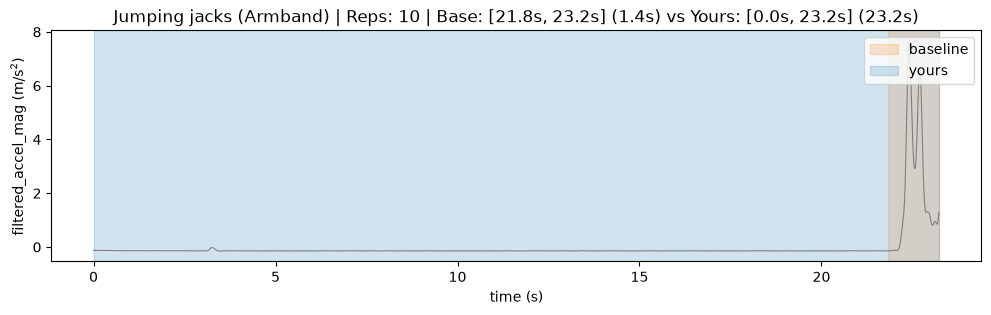

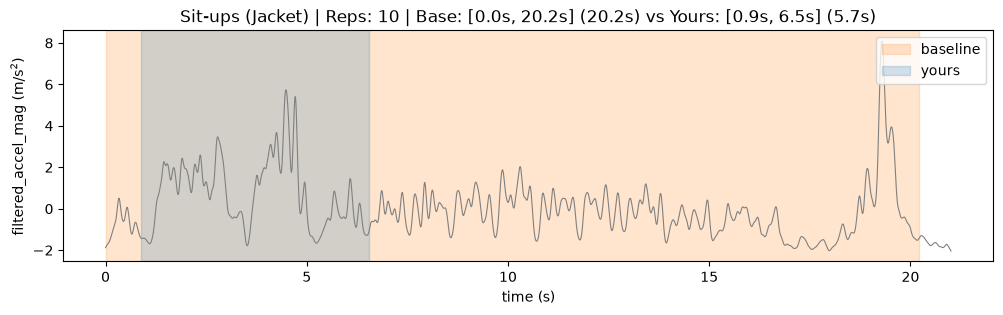

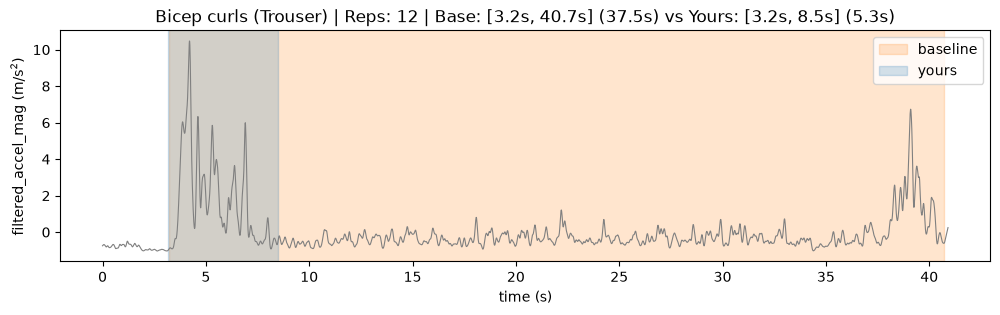

In [39]:
# Pick 6 varied recordings across exercises and placements from fit_manifest
sample_paths = [
    'data/jumping_jacks/066_2026-10-19_03-24-27.csv',  # Jumping jacks (Hand) - initial handling/still period
    'data/squats/039_2026-10-18_22-42-30.csv',         # Squats (Trouser) - handling at start & end
    'data/lat_raises/013_2026-10-19_03-07-13.csv',     # Lat raises (Armband) - repeated motion across a long recording
    'data/jumping_jacks/075_2026-10-19_03-52-57.csv',  # Jumping jacks (Armband) - baseline collapses to 1.4s
    'data/sit_ups/028_2026-10-19_02-30-25.csv',        # Sit-ups (Jacket) - possible truncation of a fragmented set
    'data/bicep_curls/020_2026-10-19_02-07-40.csv',    # Bicep curls (Trouser) - failure case (dampened placement)
]

for path in sample_paths:
    row = fit_manifest[fit_manifest['path'] == path].iloc[0]
    data, sample_rate = prepare_recording(row['path'])
    b_start, b_end = baseline_segment(data, sample_rate)
    y_start, y_end = find_exercise_segment(data, sample_rate)
    
    title = f"{row['exercise']} ({row['placement']}) | Reps: {row['reps']} | Base: [{b_start:.1f}s, {b_end:.1f}s] ({b_end-b_start:.1f}s) vs Yours: [{y_start:.1f}s, {y_end:.1f}s] ({y_end-y_start:.1f}s)"
    plot_segment(data, {
        'baseline': (b_start, b_end),
        'yours': (y_start, y_end)
    }, title=title)

#### 🛑 Interpretation of the results

**1. What does the baseline get wrong?**

The fixed 0.5 m/s² threshold returns the span from the first to the last active sample, so separated handling bursts can keep the intervening stillness. In `jumping_jacks/066`, the baseline spans [0.0 s, 25.1 s], while our method selects [6.4 s, 24.9 s]. In `squats/039`, the corresponding spans are [0.0 s, 29.2 s] and [5.4 s, 12.7 s]. These plots suggest that some activity outside the main set is removed; they do not provide manually labeled ground-truth boundaries.

In `lat_raises/013_2026-10-19_03-07-13.csv` (Armband), the baseline keeps [0.1 s, 104.6 s], whereas our method selects [0.0 s, 17.2 s]. The plot shows repeated large motion bursts throughout the later recording, so the removed 87 seconds cannot be described as idle time. This is a possible failure of the longest-block rule on a set with widely spaced movements, rather than evidence of successful tail removal. Without manually labeled boundaries, the plot does not establish the true set extent.

**2. What does our method fix, and which mechanism is responsible?**

The adaptive threshold is `max(q15 + 0.25 * (q85 - q15), 0.08)` on the 1-second moving standard deviation. A centered 2-second rolling maximum connects nearby active samples; intervals with an original-active span shorter than 3 seconds are discarded, and the longest remaining interval is selected. This can suppress isolated handling, but connected handling can remain and real repetitions can be cut off.

A separate fallback is important for `jumping_jacks/075_2026-10-19_03-52-57.csv` (Armband, **10 reported reps**). The baseline selects only [21.8 s, 23.2 s]. Here `q15 ≈ 0.00159` and `q85 ≈ 0.00310 m/s²`, so their difference is below 0.05 m/s². Our function therefore returns the **entire recording**, [0.0 s, 23.2 s]. This avoids severe truncation, but it is the near-flat fallback, not successful adaptive detection of the exercise boundaries. The end burst is consistent with handling; its physical cause cannot be established from acceleration alone.

**Implementation correction:** The initial active sample was previously counted twice as a segment start, misaligning starts and ends when the recording began active. The code now inserts that initial start only once. All plots and metrics here have been refreshed after this correction; earlier values such as adaptive/PCA MAE 3.58 are superseded.

**3. Where does our method still break?**

In `bicep_curls/020_2026-10-19_02-07-40.csv` (Trouser, 12 reported reps), our function selects only [3.2 s, 8.5 s], a 5.3-second interval. Weak coupling between arm motion and a phone at the hip is a plausible explanation for the poor segmentation. The plot alone does not establish that this interval contains the full set or prove a particular physical movement. The corrected method also selects shorter intervals for `squats/039` ([5.4 s, 12.7 s]) and `sit_ups/028` ([0.9 s, 6.5 s]); this illustrates the risk of retaining only one block of a fragmented set. Handling that blends into exercise and long pauses between repetitions can also defeat the burst and longest-segment rules.

**Recordings for Exploration Report §1:** Use `jumping_jacks/075` for baseline truncation and the full-recording fallback, and `lat_raises/013` as a possible fragmented-set failure of our method. Use `bicep_curls/020` as a failure of our method. All six plotted examples come from `fit_manifest`.

**Classification comparison:** The feature-exploration section below is unfinished. The effect of segmentation on classification has not yet been measured.


###  Assignment: Function 2: count_reps(data, sample_rate, exercise)

**Instructions:**
Define the `count_reps` function that counts the reps in one set. This is the **rep counting** axis in RUBRIC.md (exploration report §3).

- The function takes as arguments:
  - `data`: the **segment** only (already cut with the segmentation), with the same columns as above
  - `sample_rate`: the sampling frequency of the recording
  - `exercise`: the exercise name from the manifest (e.g., `'Squats'`), so you can use exercise-specific settings
- The function returns the number of reps (an integer).

**Hints and Instructions:**
- As provided, the function returns the baseline count (A1-style peaks on `filtered_accel_mag`). It counts far too many reps: for many exercises the magnitude has two peaks per rep, and noise adds more.
- Ideas to try:
  - **Pick a better signal**: one axis (e.g., the one with the largest std in the segment), or the direction that moves the most (the first principal component of `x`, `y`, `z`, e.g., with `np.linalg.svd`).
  - **Low-pass harder**: reps are slow, one every 1-4 s (0.25-1 Hz). A cutoff around 1-1.5 Hz removes most of the extra peaks.
  - **Minimum distance between peaks**: set `distance` in `find_peaks` from the rep period. You can estimate the period with the autocorrelation of the signal, or use the typical time per rep of each exercise in the training recordings (segment length / reps).
  - **Prominence**: set `prominence` relative to the std of the signal, so small bumps are not counted.
  - **Exercise-specific settings**: e.g., the typical time per rep is different for each exercise.
  - **Placement effects**: `count_reps` does not get the placement. E.g., with the phone in a pocket, a jumping jack has two jumps (feet out, feet in) per rep. A low-pass filter around 1 Hz mostly merges them into one cycle per rep.
- Tune on the training recordings only (fit + validation), never on test.

In [40]:
def count_reps(data, sample_rate, exercise=None):
    """
    Counts repetitions in an exercise segment:
    1. Extracts primary motion component using PCA/SVD on (x, y, z) to isolate
       the principal oscillatory axis (can reduce magnitude rectification double-peaks).
    2. Applies a 2nd-order Butterworth low-pass filter (1.2-1.5 Hz) to smooth high-frequency harmonics.
    3. Sets manually specified exercise-specific minimum peak distances.
    4. Detects peaks with prominence scaled to the signal's standard deviation.
    """
    if len(data) < max(int(sample_rate), 2):
        return 0

    # Project (x, y, z) onto the 1st Principal Component (dominant motion axis)
    xyz = data[['x', 'y', 'z']].values
    xyz = xyz - xyz.mean(axis=0)
    _, _, vh = np.linalg.svd(xyz, full_matrices=False)
    pca1 = xyz @ vh[0]

    # Exercise-specific low-pass cutoff (Jumping jacks are faster ~1.5 Hz; others ~1.2 Hz)
    cutoff = 1.5 if exercise == 'Jumping jacks' else 1.2
    nyq = 0.5 * sample_rate
    b, a = butter(2, min(cutoff / nyq, 0.99), btype='lowpass')
    filtered = filtfilt(b, a, pca1)

    # Manually specified minimum peak distances; no training-median derivation is recorded
    period_map = {
        'Jumping jacks': 0.65,
        'Push-ups': 1.1,
        'Ab crunches': 1.2,
        'Bicep curls': 1.2,
        'Lat raises': 1.3,
        'Squats': 1.4,
        'Sit-ups': 1.4,
        'Lunges': 1.5,
    }
    min_dist_sec = period_map.get(exercise, 1.2)
    min_dist = max(int(min_dist_sec * sample_rate), 1)

    # Prominence relative to filtered signal standard deviation
    prominence = 0.25 * np.std(filtered)

    peaks, _ = find_peaks(filtered, distance=min_dist, prominence=prominence)
    return int(len(peaks))

## Assignment-Rep Counting: Evaluate Segmentation and Rep Counting

`evaluate_rep_counter(manifest, segment_fn, count_fn)` runs a segmentation and a rep counter on every recording of `manifest` (using the true exercise from the manifest), and `rep_metrics` summarizes the errors.

1. **Baseline**: evaluate `baseline_segment` + `baseline_count_reps` on the training recordings (`train_manifest`).

2. **Tune**: improve `count_reps` and `find_exercise_segment` on the training recordings. Use `rep_metrics(results, by='exercise')` and `rep_metrics(results, by='placement')` to see where the errors are, and `bias` to see if you count too many or too few.

3. **Test**: when you are done tuning, evaluate each combination in the table below on `test_manifest` (`no_segment` = the whole recording). For §1 of your report, also evaluate the other segmentation approaches you tried, with your rep counter.

4. **Fill up** these tables.

5. **Interpretation of the results**: How much did segmentation help, and how much did the rep counter help? Which exercises and placements are hardest to count, and why?

In [41]:
# 1. Baseline evaluation on train_manifest
train_base = evaluate_rep_counter(train_manifest, baseline_segment, baseline_count_reps)
print("=== Baseline on Train Manifest ===")
print(rep_metrics(train_base))

# 2. Evaluate all combinations on test_manifest
print("\n=== Test Set Combinations ===")
combos = [
    ('none', no_segment, baseline_count_reps),
    ('baseline', baseline_segment, baseline_count_reps),
    ('yours_seg_baseline_count', find_exercise_segment, baseline_count_reps),
    ('baseline_seg_yours_count', baseline_segment, count_reps),
    ('protocol_seg_yours_count', protocol_segment, count_reps),
    ('yours_seg_yours_count', find_exercise_segment, count_reps),
]

test_results = {}
for name, seg_fn, cnt_fn in combos:
    res = evaluate_rep_counter(test_manifest, seg_fn, cnt_fn)
    test_results[name] = res
    m = rep_metrics(res)
    print(f"{name:25s} | MAE: {m['MAE']:4.2f} | within_2: {m['within_2']*100:4.1f}% | bias: {m['bias']:5.2f}")

# 3. Placement breakdown for adaptive segmentation + PCA counter on test_manifest
final_res = test_results['yours_seg_yours_count']
print("\n=== Adaptive Segmentation + PCA Counter by Placement on Test Manifest ===")
print(rep_metrics(final_res, by='placement'))
# Exercise breakdown supports the interpretation below.
print("\n=== PCA Counter + Adaptive Segmentation by Exercise on Test Manifest ===")
print(rep_metrics(final_res, by='exercise'))


=== Baseline on Train Manifest ===
recordings    301.00
MAE             7.98
within_2        0.20
bias            4.61
dtype: float64

=== Test Set Combinations ===
none                      | MAE: 7.46 | within_2: 21.0% | bias:  5.07
baseline                  | MAE: 7.24 | within_2: 20.0% | bias:  4.67
yours_seg_baseline_count  | MAE: 5.44 | within_2: 33.0% | bias:  0.50
baseline_seg_yours_count  | MAE: 4.86 | within_2: 33.0% | bias:  3.09
protocol_seg_yours_count  | MAE: 3.60 | within_2: 49.0% | bias:  0.19
yours_seg_yours_count     | MAE: 3.78 | within_2: 49.0% | bias: -1.37

=== Adaptive Segmentation + PCA Counter by Placement on Test Manifest ===
           recordings   MAE  within_2  bias
placement                                  
Armband             4  4.25      0.50 -4.25
Hand               59  3.27      0.56 -0.15
Jacket              6  4.83      0.17 -1.17
Trouser            60  4.13      0.45 -2.40

=== PCA Counter + Adaptive Segmentation by Exercise on Test Manifest ===
  

**For the test recordings:**

| Segmentation | Rep counter | MAE (reps) | Within ±2 reps | Bias |
|-|-|-|-|-|
| none (`no_segment`) | baseline | 7.46 | 21% | +5.07 |
| baseline | baseline | 7.24 | 20% | +4.67 |
| yours | baseline | 5.44 | 33% | +0.50 |
| baseline | yours | 4.86 | 33% | +3.09 |
| protocol (trim 5 s at each end) | yours | 3.60 | 49% | +0.19 |
| yours | yours | 3.78 | 49% | -1.37 |

### Rep Counting Exploration: Approaches

We compare the two implemented rep counters on the test recordings, holding **adaptive segmentation** fixed. MAE and within-±2 agreement are measured against the self-reported rep labels. A final segmentation choice still requires training/validation evidence.

| Approach | Signal | Key parameters | Rep MAE | Within ±2 reps | Notes |
|-|-|-|-|-|-|
| Baseline Peak Detection (`baseline_count_reps`) | Filtered acceleration magnitude (`filtered_accel_mag`) | Peak height > signal mean; minimum peak distance = 1.0 s | 5.44 | 33.0% | Magnitude can produce multiple peaks per repetition; residual motion can add peaks. Signed bias: +0.50 reps. |
| First Principal Component (`count_reps`, PCA / SVD) | First principal component of centered `(x, y, z)` | SVD projection; 2nd-order Butterworth low-pass applied with `filtfilt` (1.5 Hz for jumping jacks, 1.2 Hz otherwise); exercise-specific minimum peak distance; prominence = 0.25 × filtered signal std | 3.78 | 49.0% | Directional projection and filtering can reduce extra peaks. Weak motion, irregular waveforms, and segmentation errors remain. Signed bias: -1.37 reps. |

PCA-counter minimum peak distances are 0.65 s for jumping jacks, 1.1 s for push-ups, 1.2 s for ab crunches and bicep curls, 1.3 s for lat raises, 1.4 s for squats and sit-ups, and 1.5 s for lunges (default: 1.2 s). These are manually specified values; the notebook does not record a derivation from median training rep periods.

The PCA counter achieves lower MAE and higher within-±2 agreement than the baseline counter under the same adaptive segmentation. This comparison changes signal selection, filtering, peak spacing, and prominence together, so it does not establish which individual change contributed most. PCA chooses the direction of greatest acceleration variation; that direction need not correspond to repetitions when handling or other movement dominates.

A separate counter using the single Cartesian axis with the largest standard deviation has not been implemented or evaluated here, so it is excluded from the results.

**Adaptive segmentation + PCA rep counter, by placement (test recordings):**

| Placement | Recordings | MAE (reps) | Within ±2 reps |
|-|-|-|-|
| Hand | 59 | 3.27 | 56% |
| Trouser | 60 | 4.13 | 45% |
| Jacket | 6 | 4.83 | 17% |
| Armband | 4 | 4.25 | 50% |


#### 🛑 Interpretation of the results

**1. How much did segmentation help, and how much did the rep counter help?**

With baseline segmentation, changing the counter reduces MAE from 7.24 to 4.86 reps. With adaptive segmentation, it reduces MAE from 5.44 to 3.78. The PCA counter combines a directional signal, stronger low-pass filtering, exercise-specific peak distances, and prominence filtering. These comparisons measure that combined change; they do not isolate PCA's contribution or guarantee one peak per repetition.

With the PCA counter held fixed, changing from baseline to adaptive segmentation reduces MAE from 4.86 to 3.78 and signed bias from +3.09 to -1.37 reps. This is consistent with removing extraneous motion, but aggregate bias does not measure how many peaks specifically came from phone handling. Segment changes can also remove true repetitions or alter the PCA projection and peak detection.

Protocol trimming produces MAE 3.60 and 49% within ±2, compared with corrected adaptive segmentation's 3.78 and 49%. Protocol trimming therefore has the lower observed MAE by 0.18 reps, with the same rounded within-±2 rate. This small test difference is descriptive, not a basis for selecting or tuning the segmentation. The adaptive method remains the implemented method for this comparison; selecting a final approach requires training/validation evidence. The report's earlier claim that adaptive segmentation has the best test MAE must be revised.

**2. Which exercises and placements are hardest to count, and why?**

With the PCA counter and adaptive segmentation, **ab crunches** have the highest MAE (6.88, 25% within ±2), followed by bicep curls (5.60). Jumping jacks have the lowest MAE (2.08, 81% within ±2), followed by lunges (2.15). Squats have MAE 3.66 and 47% within ±2, so they are not among the easiest exercises in these results. Weak movement at the phone and differences in motion waveform are possible explanations; the aggregate metrics alone cannot establish the mechanism.

Jacket has the highest placement MAE (4.83, 17% within ±2), but includes only 6 test recordings; Armband has only 4. Hand and Trouser have 59 and 60 recordings, respectively. These small, differently composed groups do not establish a general placement ranking. Loose clothing motion and a phone placed away from the moving limb are plausible sources of error that need recording-level inspection.

These rep-counting evaluations use the **true exercise label** from the manifest. They are not end-to-end results using classifier predictions. Percentages above follow `rep_metrics`, which rounds proportions to two decimal places before display.


###  Assignment: Function 3: add_my_features(window, sample_rate)

This is where you do your **feature engineering** (exploration report §2). The function receives one window and returns a one-row DataFrame of features.

**Hints and Instructions:**
- The window has the columns `time`, `x`, `y`, `z`, `accel_mag`, and `filtered_accel_mag`.
- Start from the baseline features in `add_features` (7 statistics of the filtered magnitude, from A2) and add your own as new columns. As provided, the function only returns the baseline, so you can run the whole notebook before writing any features.
- Ideas to try:
  - **Which axis moves**: std of `x`, `y`, `z`, and the share of the largest one (a bicep curl in the hand moves mostly along one axis; a jumping jack moves along all of them)
  - **Rep rate**: dominant frequency of the filtered magnitude or of one axis (use `np.fft.rfft` and `np.fft.rfftfreq(len(signal), 1/sample_rate)`). Jumping jacks are fast, squats are slow
  - **Correlation between axes**: `np.corrcoef`
  - **Intensity**: RMS, range, number of peaks per second
- Gravity is removed, so the features cannot directly tell lying down (sit-ups) from standing (squats).
- Some features can be `NaN` (e.g., the correlation of a flat window). Return 0 instead, because most models cannot handle `NaN`.
- Aim for ~5-10 features of your own on top of the 7 baseline features. Keep the ones that help and document the ones you dropped.

In [42]:
def add_my_features(window, sample_rate):
    features = add_features(window)   # baseline: avg, max, med, min, q25, q75, std of filtered_accel_mag

    ######## TODO ###############
    # Add your own features as new columns, e.g.
    # features['std_x'] = ...
    #############################
    
    axes = window[['x', 'y', 'z']].to_numpy(dtype=float)

    # 1–3: Per-axis standard deviation.
    axis_std = axes.std(axis=0)
    for i, axis in enumerate(['x', 'y', 'z']):
        features[f'std_{axis}'] = axis_std[i]

    # 4–6: Per-axis interquartile range.
    # Unlike standard deviation, IQR is less sensitive to extreme values.
    axis_iqr = (
        np.percentile(axes, 75, axis=0)
        - np.percentile(axes, 25, axis=0)
    )
    for i, axis in enumerate(['x', 'y', 'z']):
        features[f'iqr_{axis}'] = axis_iqr[i]

    # 7–9: Correlation between pairs of axes.
    # Use zero when either axis is effectively constant.
    for i, j, name in [
        (0, 1, 'corr_xy'),
        (0, 2, 'corr_xz'),
        (1, 2, 'corr_yz'),
    ]:
        if axis_std[i] > 1e-8 and axis_std[j] > 1e-8:
            features[name] = np.corrcoef(axes[:, i], axes[:, j])[0, 1]
        else:
            features[name] = 0.0

    # 10: Dominant frequency of the most active axis.
    # A signed axis avoids the frequency doubling magnitude can introduce.
    dominant_frequency = 0.0

    if len(axes) >= 4 and axis_std.max() > 1e-8:
        active_axis = np.argmax(axis_std)
        signal = axes[:, active_axis]
        signal = signal - signal.mean()

        # Reduce spectral leakage caused by the window boundaries.
        tapered_signal = signal * np.hanning(len(signal))

        frequencies = np.fft.rfftfreq(len(signal), d=1.0 / sample_rate)
        power = np.abs(np.fft.rfft(tapered_signal)) ** 2

        # Search a plausible exercise-motion band.
        valid = (frequencies >= 0.2) & (frequencies <= 3.0)

        if valid.any() and power[valid].max() > 1e-12:
            dominant_frequency = frequencies[valid][np.argmax(power[valid])]

    features['dominant_freq'] = dominant_frequency

    return features

#### Helper functions (provided)

`train_decision_tree`, `train_random_forest`, and `evaluate` take an optional `features` argument (a list of column names). By default, the training functions use every feature column (everything except `exercise` and `recording`), and `evaluate` uses the same columns the model was trained on. Unlike A2, the training functions do not split the data. You pass them the training windows, and then you evaluate on other recordings with `evaluate`.

Use `train_random_forest` (fixed settings) to compare window lengths, features, and segmentation. Use `train_decision_tree` in Classification1.

In [43]:
BASELINE_FEATURES = ['avg', 'max', 'med', 'min', 'q25', 'q75', 'std']

def feature_columns(frames):
    return [c for c in frames.columns if c not in ('exercise', 'recording')]


def evaluate(model, frames, features=None, verbose=True):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))
    X_test = frames[list(features)]

    # Extract target column
    y_test = frames['exercise']

    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    if verbose:
        print(classification_report(y_test, pred, zero_division=0))
        print("Accuracy:", acc)
    return acc, pred

In [44]:
def train_decision_tree(frames, max_depth=5, criterion='entropy', features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['exercise']

    # Create and train the model on all the windows in frames
    dt_model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=42).fit(X, y)
    return dt_model


def train_random_forest(frames, features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['exercise']

    # A random forest with fixed settings, to compare window lengths, features, and segmentation
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X, y)
    return rf_model

## Assignment-Feature Exploration: Window Length, Features, and Segmentation

Before comparing models, choose the window length and the feature set (exploration report §2), and check the effect of your segmentation on classification (§1). Train with `train_random_forest` on the **fit** windows and evaluate on the **validation** windows. We use a random forest here because it uses many features at once, so the effect of a feature set is easier to see than with a small decision tree.

`build_feature_frames` goes over all 430 recordings (about 1-2 minutes). Build it once per setting for the whole `manifest`, then use `select_recordings` to get the fit, validation, and test windows.

1. **Window length**: Build the feature frames with at least three window lengths (e.g., 2 s, 4 s, 6 s), using `find_exercise_segment` and the baseline features (`baseline_features`). Train on fit, evaluate on validation.

2. **Features**: Write `add_my_features` (Function 3) and rebuild. Compare the baseline features to your features at the same window length. Try adding and removing features (pass `features=[...]` to `train_random_forest`) and use the classification report to see which exercises each feature helps.

3. **Segmentation**: Rebuild with your features and `no_segment` instead of `find_exercise_segment`, and compare.

4. **Lock in** one window length, one feature set, and one segmentation, and use them in all the sections below.

5. **Fill up** this table.

6. **Interpretation of the results**: Which window length worked best, and why do you think so? Which features helped, and which exercises did they separate? Did segmentation help the classifier?

In [45]:
# Extra code cell used to test the different window sizes and their impact

window_results = []

for window_sec in [2, 4, 6]:
    frames = build_feature_frames(
        train_manifest,
        window_sec,
        find_exercise_segment,
        baseline_features
    )

    fit_frames = select_recordings(frames, fit_manifest)
    val_frames = select_recordings(frames, val_manifest)

    model = train_random_forest(
        fit_frames,
        features=BASELINE_FEATURES
    )

    accuracy, _ = evaluate(
        model,
        val_frames,
        features=BASELINE_FEATURES,
        verbose=False
    )

    window_results.append({
        'Window length (s)': window_sec,
        'Validation accuracy': accuracy
    })

window_results = pd.DataFrame(window_results)
display(window_results)

,Window length (s),Validation accuracy
0,2,0.478461
1,4,0.483354
2,6,0.519841


In [ ]:
# Hints, step by step:
# frames = build_feature_frames(manifest, 4, find_exercise_segment, baseline_features)
# fit_frames, val_frames = select_recordings(frames, fit_manifest), select_recordings(frames, val_manifest)
# model = train_random_forest(fit_frames, features=BASELINE_FEATURES); evaluate(model, val_frames)
# Repeat for other window lengths, then with add_my_features, then with no_segment
# Lock in WINDOW_SEC and your final frames, then for the rest of the notebook:
#   FEATURES = feature_columns(frames)
#   train_frames, test_frames = select_recordings(frames, train_manifest), select_recordings(frames, test_manifest)

# Build all candidate features once.
WINDOW_SEC = 6

frames = build_feature_frames(
    train_manifest,
    WINDOW_SEC,
    find_exercise_segment,
    add_my_features
)

fit_frames = select_recordings(frames, fit_manifest)
val_frames = select_recordings(frames, val_manifest)

candidate_features = [
    'std_x', 'std_y', 'std_z',
    'iqr_x', 'iqr_y', 'iqr_z',
    'corr_xy', 'corr_xz', 'corr_yz',
    'dominant_freq'
]

# Check that the candidate feature values are usable.
all_features = BASELINE_FEATURES + candidate_features

assert np.isfinite(
    fit_frames[all_features].to_numpy()
).all(), "Fit features contain missing or infinite values."

assert np.isfinite(
    val_frames[all_features].to_numpy()
).all(), "Validation features contain missing or infinite values."


# 1. Evaluate the baseline once.
print("BASELINE: seven original features\n")

baseline_model = train_random_forest(
    fit_frames,
    features=BASELINE_FEATURES
)

baseline_acc, baseline_pred = evaluate(
    baseline_model,
    val_frames,
    features=BASELINE_FEATURES
)

baseline_report = classification_report(
    val_frames['exercise'],
    baseline_pred,
    output_dict=True,
    zero_division=0
)

summary_rows = [{
    'Added feature': 'Baseline',
    'Validation accuracy (%)': baseline_acc * 100,
    'Change (percentage points)': 0.0
}]

exercise_rows = []

# Preserve predictions for later confusion-matrix comparisons.
feature_predictions = {'Baseline': baseline_pred}


# 2. Test each feature separately.
for feature in candidate_features:
    print("\n" + "=" * 65)
    print(f"BASELINE + {feature}\n")

    selected_features = BASELINE_FEATURES + [feature]

    model = train_random_forest(
        fit_frames,
        features=selected_features
    )

    trial_acc, trial_pred = evaluate(
        model,
        val_frames,
        features=selected_features
    )

    feature_predictions[feature] = trial_pred

    change = (trial_acc - baseline_acc) * 100

    print(f"\nBaseline accuracy: {baseline_acc:.2%}")
    print(f"With {feature}: {trial_acc:.2%}")
    print(f"Change: {change:+.2f} percentage points")

    summary_rows.append({
        'Added feature': feature,
        'Validation accuracy (%)': trial_acc * 100,
        'Change (percentage points)': change
    })

    # Compare per-exercise recall and F1 against the baseline.
    trial_report = classification_report(
        val_frames['exercise'],
        trial_pred,
        output_dict=True,
        zero_division=0
    )

    for exercise in sorted(val_frames['exercise'].unique()):
        exercise_rows.append({
            'Added feature': feature,
            'Exercise': exercise,
            'Baseline recall': baseline_report[exercise]['recall'],
            'New recall': trial_report[exercise]['recall'],
            'Recall change (pp)': (
                trial_report[exercise]['recall']
                - baseline_report[exercise]['recall']
            ) * 100,
            'Baseline F1': baseline_report[exercise]['f1-score'],
            'New F1': trial_report[exercise]['f1-score'],
            'F1 change': (
                trial_report[exercise]['f1-score']
                - baseline_report[exercise]['f1-score']
            )
        })


# 3. Display overall results.
feature_summary = pd.DataFrame(summary_rows).sort_values(
    'Validation accuracy (%)',
    ascending=False
).reset_index(drop=True)

exercise_changes = pd.DataFrame(exercise_rows)

print("\nOVERALL FEATURE COMPARISON")
display(feature_summary.round(2))


# 4. Display which exercises improved or declined for each feature.
print("\nPER-EXERCISE CHANGES")

for feature in candidate_features:
    print(f"\nBaseline + {feature}")

    comparison = exercise_changes[
        exercise_changes['Added feature'] == feature
    ].sort_values('F1 change', ascending=False)

    display(comparison.drop(columns='Added feature').round(3))

    

BASELINE: seven original features

               precision    recall  f1-score   support

  Ab crunches       0.00      0.00      0.00        36
  Bicep curls       0.71      0.33      0.45        61
Jumping jacks       0.96      0.93      0.95        85
   Lat raises       0.18      0.09      0.12        23
       Lunges       0.30      0.35      0.33        62
     Push-ups       0.20      0.20      0.20        45
      Sit-ups       0.30      0.31      0.31        35
       Squats       0.53      0.76      0.62       157

     accuracy                           0.52       504
    macro avg       0.40      0.37      0.37       504
 weighted avg       0.50      0.52      0.49       504

Accuracy: 0.5198412698412699

BASELINE + std_x

               precision    recall  f1-score   support

  Ab crunches       0.25      0.03      0.05        36
  Bicep curls       0.77      0.28      0.41        61
Jumping jacks       0.96      0.93      0.95        85
   Lat raises       0.30      0.1

,Added feature,Validation accuracy (%),Change (percentage points)
0,iqr_x,53.97,1.98
1,std_y,52.18,0.20
2,Baseline,51.98,0.00
3,iqr_y,51.19,-0.79
4,corr_xy,50.40,-1.59
5,corr_xz,49.80,-2.18
6,std_x,49.60,-2.38
7,std_z,49.60,-2.38
8,dominant_freq,49.60,-2.38
9,corr_yz,48.81,-3.17



PER-EXERCISE CHANGES

Baseline + std_x


,Exercise,Baseline recall,New recall,Recall change (pp),Baseline F1,New F1,F1 change
4,Lunges,0.355,0.452,9.677,0.326,0.394,0.068
3,Lat raises,0.087,0.130,4.348,0.118,0.182,0.064
0,Ab crunches,0.000,0.028,2.778,0.000,0.050,0.050
2,Jumping jacks,0.929,0.929,0.000,0.946,0.946,0.000
6,Sit-ups,0.314,0.286,-2.857,0.306,0.294,-0.011
1,Bicep curls,0.328,0.279,-4.918,0.449,0.410,-0.040
5,Push-ups,0.200,0.133,-6.667,0.202,0.133,-0.069
7,Squats,0.758,0.675,-8.280,0.621,0.551,-0.071



Baseline + std_y


,Exercise,Baseline recall,New recall,Recall change (pp),Baseline F1,New F1,F1 change
8,Ab crunches,0.000,0.083,8.333,0.000,0.125,0.125
11,Lat raises,0.087,0.174,8.696,0.118,0.235,0.118
13,Push-ups,0.200,0.356,15.556,0.202,0.302,0.100
12,Lunges,0.355,0.371,1.613,0.326,0.397,0.071
14,Sit-ups,0.314,0.343,2.857,0.306,0.312,0.006
10,Jumping jacks,0.929,0.929,0.000,0.946,0.940,-0.006
15,Squats,0.758,0.707,-5.096,0.621,0.594,-0.028
9,Bicep curls,0.328,0.246,-8.197,0.449,0.353,-0.096


... (15 outputs left out)

,Exercise,Baseline recall,New recall,Recall change (pp),Baseline F1,New F1,F1 change
75,Lat raises,0.087,0.130,4.348,0.118,0.176,0.059
77,Push-ups,0.200,0.222,2.222,0.202,0.250,0.048
72,Ab crunches,0.000,0.000,0.000,0.000,0.000,0.000
74,Jumping jacks,0.929,0.929,0.000,0.946,0.940,-0.006
78,Sit-ups,0.314,0.343,2.857,0.306,0.293,-0.013
73,Bicep curls,0.328,0.295,-3.279,0.449,0.419,-0.031
76,Lunges,0.355,0.306,-4.839,0.326,0.286,-0.040
79,Squats,0.758,0.694,-6.369,0.621,0.568,-0.054



SEGMENTATION COMPARISON


,Segmentation,Window length (s),Features,Validation windows,Validation accuracy (%)
0,Adaptive (ours),6,Baseline + iqr_x,504,53.97
1,Fixed threshold (baseline),6,Baseline + iqr_x,731,47.74
2,None,6,Baseline + iqr_x,801,47.57


Adaptive vs none: +6.40 percentage points
Adaptive vs fixed threshold: +6.23 percentage points


In [48]:
# 5. Compare segmentation methods with the selected features.
WINDOW_SEC = 6
FEATURES = BASELINE_FEATURES + ['iqr_x']

segmentation_methods = {
    'Adaptive (ours)': find_exercise_segment,
    'Fixed threshold (baseline)': baseline_segment,
    'None': no_segment
}

segmentation_rows = []

for name, segment_fn in segmentation_methods.items():
    # Rebuild windows because each method selects a different
    # portion of each recording.
    seg_frames = build_feature_frames(
        train_manifest,
        WINDOW_SEC,
        segment_fn,
        add_my_features
    )

    seg_fit = select_recordings(seg_frames, fit_manifest)
    seg_val = select_recordings(seg_frames, val_manifest)

    # Train a separate model for each segmentation approach,
    # using identical Random Forest settings.
    seg_model = train_random_forest(
        seg_fit,
        features=FEATURES
    )

    seg_acc, _ = evaluate(
        seg_model,
        seg_val,
        features=FEATURES,
        verbose=False
    )

    segmentation_rows.append({
        'Segmentation': name,
        'Window length (s)': WINDOW_SEC,
        'Features': 'Baseline + iqr_x',
        'Validation windows': len(seg_val),
        'Validation accuracy (%)': seg_acc * 100
    })

segmentation_results = pd.DataFrame(segmentation_rows)

print("\nSEGMENTATION COMPARISON")
display(segmentation_results.round(2))

# Positive differences mean adaptive segmentation performed better.
accuracy_by_method = segmentation_results.set_index(
    'Segmentation'
)['Validation accuracy (%)']

adaptive_acc = accuracy_by_method['Adaptive (ours)']

print(
    "Adaptive vs none: "
    f"{adaptive_acc - accuracy_by_method['None']:+.2f} percentage points"
)

print(
    "Adaptive vs fixed threshold: "
    f"{adaptive_acc - accuracy_by_method['Fixed threshold (baseline)']:+.2f} "
    "percentage points"
)


SEGMENTATION COMPARISON


,Segmentation,Window length (s),Features,Validation windows,Validation accuracy (%)
0,Adaptive (ours),6,Baseline + iqr_x,504,53.97
1,Fixed threshold (baseline),6,Baseline + iqr_x,731,47.74
2,None,6,Baseline + iqr_x,801,47.57


Adaptive vs none: +6.40 percentage points
Adaptive vs fixed threshold: +6.23 percentage points


**For the validation recordings:**

| Segmentation | Window length | Features | Window accuracy (validation) |
|-|-|-|-|
| yours | 2 s | baseline | 47.85% |
| yours | 4 s | baseline | 48.33% |
| yours | 6 s | baseline | 51.98% |
| yours | 6 s | baseline + iqr_x| 53.97% |
| none | 6 s | baseline + iqr_x | 47.57% |


#### 🛑 Interpretation of the results

**Write Below:**

The best window length was 6 seconds at 51.98% accuracy, compared to 47.85% for 2 seconds, and 48.33% for 4 seconds. Longer windows can capture more complete repetitions, making extracted features more representative of the exercise's movement patterns. Adding iqr_x gave us the biggest individual improvement, increasing validation accuracy from 51.98% to 53.97%, and helped improve sit-ups, bicep curls, and lunges, getting an F1 gain of around 0.07-0.13. Adding std_y also improved our overall accuracy, and helped separate push-ups and lat raises, although other exercises ended up reducing overall accuracy. Segmentation did help the classifer, as when testing without it, we ended up lowering our score from our baseline of 51.98%, to 47.57%.

## Assignment-Classification1: Decision Tree

In this section, you tune a decision tree and test it on the test recordings. The steps are as follows:

1. **Grid Search**: Do grid search for tuning the hyperparameters (`max_depth` and `criterion` in `train_decision_tree`). Train on the **fit** windows and pick the hyperparameters with the highest accuracy on the **validation** windows. Do not pick hyperparameters by looking at the test accuracy: it is your test set.

2. **Test**: Retrain the decision tree with the best hyperparameters on all the **training** windows (fit + validation), and evaluate it on the **test** windows. Do the same for the default hyperparameters.

3. **Performance Visualization**: Display the confusion matrix of the test windows with matplotlib's `ConfusionMatrixDisplay`. Each row corresponds to a true exercise, and each column to a predicted exercise. With 8 exercises, use a large figure and rotate the labels (`xticks_rotation='vertical'`).

4. **Decision Tree Visualization**: Visualize the decision tree using the `viz_tree` function (loaded from util.py). Pass `list(model.classes_)` as the class names, so the names match the model's order of the classes.

5. **Fill up** this table.

6. **Interpretation of the results**: Which exercises are easy to recognize, and which are confused with each other? Why? What did you learn from hyperparameter tuning?

DECISION TREE GRID SEARCH


,max_depth,criterion,Validation accuracy (%)
3,3,gini,49.21
8,12,entropy,48.21
2,3,entropy,47.62
6,8,entropy,47.62
10,20,entropy,47.42
9,12,gini,46.03
5,5,gini,45.04
7,8,gini,45.04
4,5,entropy,41.47
11,20,gini,40.87


Selected: max_depth=3, criterion='gini'

DEFAULT DECISION TREE — TEST RESULTS
               precision    recall  f1-score   support

  Ab crunches       0.00      0.00      0.00        37
  Bicep curls       0.06      0.01      0.02        95
Jumping jacks       0.83      0.87      0.85       124
   Lat raises       0.00      0.00      0.00        41
       Lunges       0.30      0.54      0.39        82
     Push-ups       0.00      0.00      0.00        65
      Sit-ups       0.49      0.22      0.30        95
       Squats       0.44      0.72      0.54       283

     accuracy                           0.46       822
    macro avg       0.26      0.29      0.26       822
 weighted avg       0.37      0.46      0.39       822

Accuracy: 0.4586374695863747

SELECTED DECISION TREE — TEST RESULTS
               precision    recall  f1-score   support

  Ab crunches       0.00      0.00      0.00        37
  Bicep curls       0.05      0.01      0.02        95
Jumping jacks       0.84 

,Model,max_depth,criterion,Window accuracy (validation %),Window accuracy (test %)
0,Default,5,entropy,41.47,45.86
1,Selected using validation,3,gini,49.21,40.63


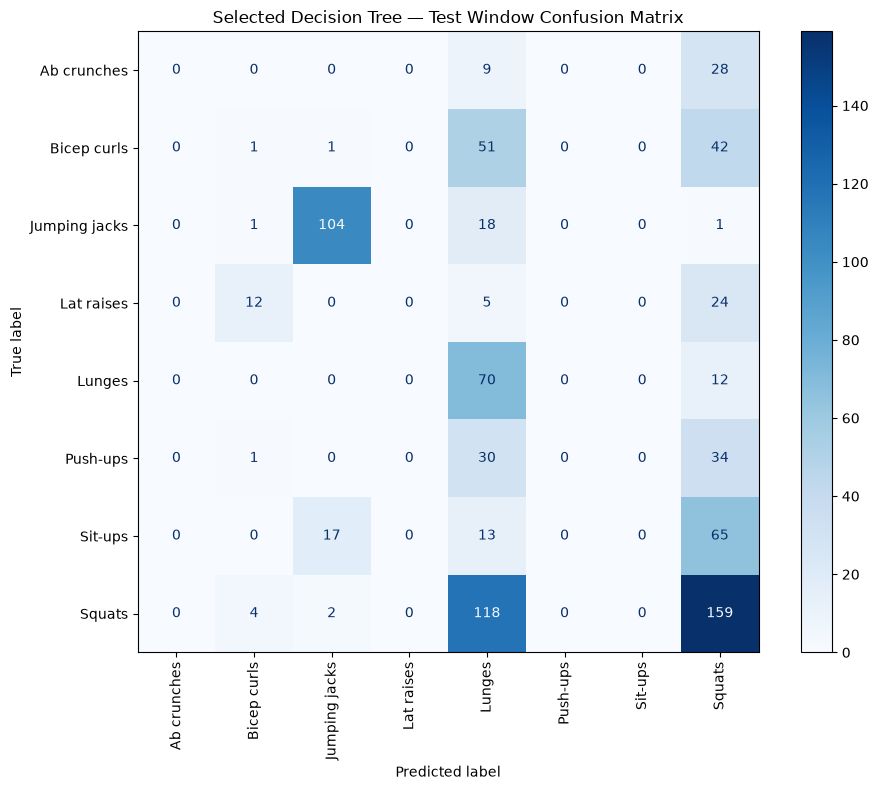

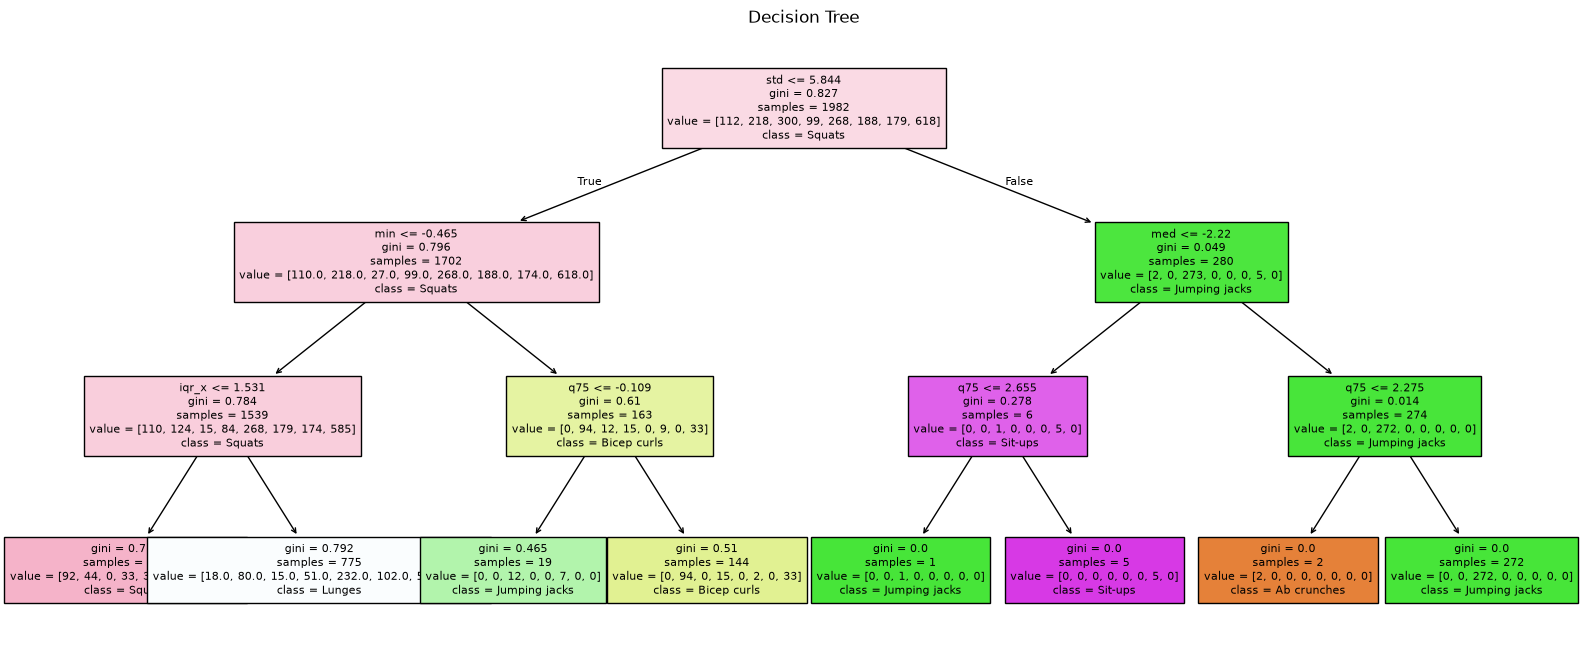

In [49]:
# Hints, step by step:
# Grid search: for each max_depth and criterion, train on fit_frames, evaluate on val_frames (verbose=False)
# Retrain the best (and the default) on train_frames, evaluate on test_frames
# Display the confusion matrix of the test windows
# Visualize the tree: viz_tree(model, train_frames[FEATURES], list(model.classes_))

########################### TODO ##########################

WINDOW_SEC = 6
FEATURES = BASELINE_FEATURES + ['iqr_x']

# Include all recordings so test frames are available for final evaluation.
frames = build_feature_frames(
    manifest,
    WINDOW_SEC,
    find_exercise_segment,
    add_my_features
)

fit_frames = select_recordings(frames, fit_manifest)
val_frames = select_recordings(frames, val_manifest)
train_frames = select_recordings(frames, train_manifest)
test_frames = select_recordings(frames, test_manifest)


# 2. Grid search using ONLY fit and validation recordings.
# Test several tree depths and both splitting criteria.
depth_options = [2, 3, 5, 8, 12, 20]
criterion_options = ['entropy', 'gini']

dt_search_rows = []

for depth in depth_options:
    for criterion in criterion_options:
        candidate_model = train_decision_tree(
            fit_frames,
            max_depth=depth,
            criterion=criterion,
            features=FEATURES
        )

        val_acc, _ = evaluate(
            candidate_model,
            val_frames,
            features=FEATURES,
            verbose=False
        )

        dt_search_rows.append({
            'max_depth': depth,
            'criterion': criterion,
            'validation_accuracy': val_acc
        })

# Select the highest validation accuracy.
# Ties keep the first result, favoring shallower depths in this grid.
best_result = max(
    dt_search_rows,
    key=lambda row: row['validation_accuracy']
)

best_depth = best_result['max_depth']
best_criterion = best_result['criterion']
best_val_acc = best_result['validation_accuracy']

# The notebook's default settings are included in the search.
default_result = next(
    row for row in dt_search_rows
    if row['max_depth'] == 5 and row['criterion'] == 'entropy'
)
default_val_acc = default_result['validation_accuracy']

dt_search_results = pd.DataFrame(dt_search_rows)
dt_search_display = dt_search_results.assign(
    validation_accuracy=dt_search_results['validation_accuracy'] * 100
).rename(columns={
    'validation_accuracy': 'Validation accuracy (%)'
})

print("DECISION TREE GRID SEARCH")
display(
    dt_search_display.sort_values(
        'Validation accuracy (%)',
        ascending=False,
        kind='stable'
    ).round(2)
)

print(
    f"Selected: max_depth={best_depth}, "
    f"criterion='{best_criterion}'"
)


# 3. Retrain default and selected trees on ALL training recordings.
# train_frames includes both fit and validation recordings.
dt_default = train_decision_tree(
    train_frames,
    max_depth=5,
    criterion='entropy',
    features=FEATURES
)

dt_best = train_decision_tree(
    train_frames,
    max_depth=best_depth,
    criterion=best_criterion,
    features=FEATURES
)


# 4. Evaluate the two final models on test recordings.
print("\nDEFAULT DECISION TREE — TEST RESULTS")
default_test_acc, default_test_pred = evaluate(
    dt_default,
    test_frames,
    features=FEATURES
)

print("\nSELECTED DECISION TREE — TEST RESULTS")
best_test_acc, best_test_pred = evaluate(
    dt_best,
    test_frames,
    features=FEATURES
)

dt_comparison = pd.DataFrame([
    {
        'Model': 'Default',
        'max_depth': 5,
        'criterion': 'entropy',
        'Window accuracy (validation %)': default_val_acc * 100,
        'Window accuracy (test %)': default_test_acc * 100
    },
    {
        'Model': 'Selected using validation',
        'max_depth': best_depth,
        'criterion': best_criterion,
        'Window accuracy (validation %)': best_val_acc * 100,
        'Window accuracy (test %)': best_test_acc * 100
    }
])

print("\nDECISION TREE COMPARISON")
display(dt_comparison.round(2))


# 5. Plot the selected tree's test-window confusion matrix.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    test_frames['exercise'],
    best_test_pred,
    labels=dt_best.classes_,
    display_labels=dt_best.classes_,
    cmap='Blues',
    xticks_rotation='vertical',
    values_format='d',
    ax=ax
)

ax.set_title('Selected Decision Tree — Test Window Confusion Matrix')
plt.tight_layout()
plt.show()


# 6. Visualize the selected tree.
# The provided helper displays only the top levels for readability.
viz_tree(
    dt_best,
    train_frames[FEATURES],
    list(dt_best.classes_)
)
plt.show()

**For the data in the dataset:**

| Hyperparameters | Window accuracy (validation) | Window accuracy (test) |
|-|-|-|
| Default (max_depth=5, criterion='entropy') | 41.47% | 45.86% |
| (max_depth=3, criterion='gini')  | 49.21% | 40.63% |


#### 🛑 Interpretation of the results

**Write Below:**

Jumping jacks were recognized most reliably, and lunges also were recognized fairly well. However, the model had confusion with Squats, as it predicted lunges for a lot of our squats. There was also confusion with ab crunches, bicep curls, lat raises, push-ups, and sit-ups as those barely had any correct identifications. This might be because some exercises it can be hard to find valuable signals from it based on the sensor and type of exercise. This means our selected features and shallow tree don't separate several exercises very well. From hyperparameter tuning, we got max_depth = 3 with gini, achieving 49.21% validation accuracy, compared to 41.47% with the default settings. However, after retraining, our selected tree ended up getting a worse test accuracy of 40.63% compared to the 45.86% default. Validation improvement did not carry over to test recordings, and reflects differences between recording sets and selection effects from comparing multiple configurations on a limited validation set.

## Assignment-Classification2: A New Classifier

Repeat section Assignment-Classification1 with a different classifier, using the same window length and feature set. It could be Random Forest, kNN, Logistic regression, or any other classifier of your choice (add its import to the imports block). Tune its key hyperparameters the same way (fit → validation), then retrain on all the training windows and evaluate on the test windows. Finally, compare it with the decision tree (model exploration, exploration report §2): did the better model help all exercises equally, or did the gain concentrate on specific exercises?

Notes:
- kNN, Logistic Regression, and SVM are sensitive to feature scale, so standardize the features first (e.g., `make_pipeline(StandardScaler(), KNeighborsClassifier())`).
- The classes are imbalanced (106 squats vs 19 lat raises). Many models have `class_weight='balanced'`. Try it and see what happens to the small classes.

Completed 1/24: validation accuracy = 49.60%
Completed 2/24: validation accuracy = 41.47%
Completed 3/24: validation accuracy = 49.21%
Completed 4/24: validation accuracy = 40.48%
Completed 5/24: validation accuracy = 51.59%
Completed 6/24: validation accuracy = 45.24%
Completed 7/24: validation accuracy = 51.39%
Completed 8/24: validation accuracy = 45.04%
Completed 9/24: validation accuracy = 52.98%
Completed 10/24: validation accuracy = 49.80%
Completed 11/24: validation accuracy = 53.37%
Completed 12/24: validation accuracy = 49.01%
Completed 13/24: validation accuracy = 50.20%
Completed 14/24: validation accuracy = 40.87%
Completed 15/24: validation accuracy = 49.40%
Completed 16/24: validation accuracy = 40.48%
Completed 17/24: validation accuracy = 51.39%
Completed 18/24: validation accuracy = 46.63%
Completed 19/24: validation accuracy = 51.19%
Completed 20/24: validation accuracy = 45.83%
Completed 21/24: validation accuracy = 53.97%
Completed 22/24: validation accuracy = 49.4

,n_estimators,max_depth,min_samples_leaf,class_weight,Validation accuracy (%)
20,200,NaN,1,NaN,53.97
10,100,NaN,3,NaN,53.37
22,200,NaN,3,NaN,53.37
8,100,NaN,1,NaN,52.98
4,100,10.0,1,NaN,51.59
6,100,10.0,3,NaN,51.39
16,200,10.0,1,NaN,51.39
18,200,10.0,3,NaN,51.19
12,200,5.0,1,NaN,50.20
9,100,NaN,1,balanced,49.80



Selected parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'class_weight': None}
Selected validation accuracy: 53.97%

SELECTED RANDOM FOREST — TEST RESULTS
               precision    recall  f1-score   support

  Ab crunches       0.24      0.14      0.17        37
  Bicep curls       0.31      0.17      0.22        95
Jumping jacks       0.80      0.89      0.84       124
   Lat raises       0.04      0.02      0.03        41
       Lunges       0.32      0.39      0.35        82
     Push-ups       0.27      0.31      0.29        65
      Sit-ups       0.27      0.20      0.23        95
       Squats       0.53      0.64      0.58       283

     accuracy                           0.47       822
    macro avg       0.35      0.34      0.34       822
 weighted avg       0.43      0.47      0.44       822

Accuracy: 0.4659367396593674

MODEL COMPARISON


,Model,Hyperparameters,Window accuracy (validation %),Window accuracy (test %)
0,Decision Tree (validation-selected),"max_depth=3, criterion=gini",49.21,40.63
1,Random Forest (validation-selected),"{'n_estimators': 200, 'max_depth': None, 'min_...",53.97,46.59


Random Forest minus Decision Tree test accuracy: +5.96 percentage points

PER-EXERCISE COMPARISON


,Exercise,Decision Tree F1,Random Forest F1,F1 change
5,Push-ups,0.000,0.288,0.288
6,Sit-ups,0.000,0.230,0.230
1,Bicep curls,0.018,0.218,0.200
0,Ab crunches,0.000,0.172,0.172
7,Squats,0.491,0.576,0.085
3,Lat raises,0.000,0.030,0.030
2,Jumping jacks,0.839,0.843,0.004
4,Lunges,0.354,0.350,-0.004


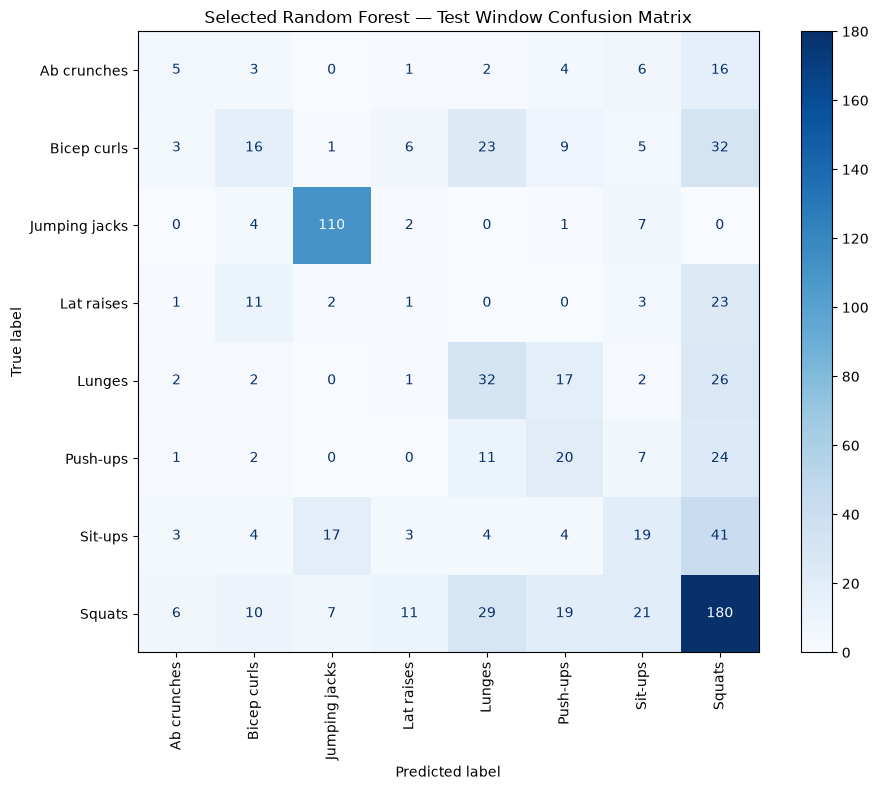

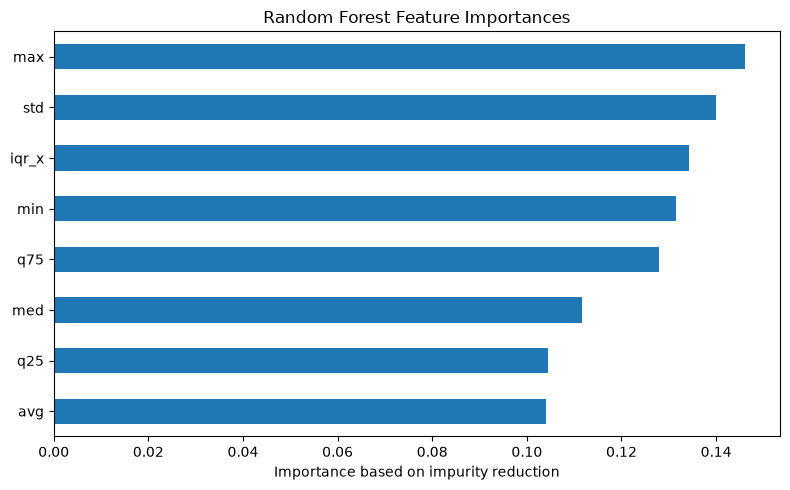

In [50]:
# Hints, step by step:
# Grid search the key hyperparameters of the new classifier: fit on fit_frames[FEATURES], evaluate on val_frames
# Retrain the best on train_frames, evaluate on test_frames
# Display the confusion matrix
# Visualize the model if it makes sense (feature importances for a forest)

########################### TODO ##########################

FEATURES = BASELINE_FEATURES + ['iqr_x']

# Use separate variable names so the Decision Tree results are preserved.
rf_parameter_options = [
    {
        'n_estimators': n_trees,
        'max_depth': depth,
        'min_samples_leaf': min_leaf,
        'class_weight': weight
    }
    for n_trees in [100, 200]
    for depth in [5, 10, None]
    for min_leaf in [1, 3]
    for weight in [None, 'balanced']
]


# 2. Tune using ONLY fit and validation recordings.
rf_search_rows = []
rf_best_val_acc = -1.0
rf_best_params = None

for index, params in enumerate(rf_parameter_options, start=1):
    candidate_forest = RandomForestClassifier(
        **params,
        criterion='gini',
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )

    candidate_forest.fit(
        fit_frames[FEATURES],
        fit_frames['exercise']
    )

    val_acc, _ = evaluate(
        candidate_forest,
        val_frames,
        features=FEATURES,
        verbose=False
    )

    rf_search_rows.append({
        **params,
        'Validation accuracy (%)': val_acc * 100
    })

    # Ties keep the first configuration encountered.
    if val_acc > rf_best_val_acc:
        rf_best_val_acc = val_acc
        rf_best_params = params.copy()

    print(
        f"Completed {index}/{len(rf_parameter_options)}: "
        f"validation accuracy = {val_acc:.2%}"
    )

rf_search_results = pd.DataFrame(rf_search_rows)

print("\nRANDOM FOREST GRID SEARCH")
display(
    rf_search_results.sort_values(
        'Validation accuracy (%)',
        ascending=False,
        kind='stable'
    ).round(2)
)

print("\nSelected parameters:", rf_best_params)
print(f"Selected validation accuracy: {rf_best_val_acc:.2%}")


# 3. Retrain the selected forest on ALL training recordings.
rf_best = RandomForestClassifier(
    **rf_best_params,
    criterion='gini',
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_best.fit(
    train_frames[FEATURES],
    train_frames['exercise']
)


# 4. Evaluate the selected forest on test recordings.
print("\nSELECTED RANDOM FOREST — TEST RESULTS")

rf_test_acc, rf_test_pred = evaluate(
    rf_best,
    test_frames,
    features=FEATURES
)

# Evaluate the already-trained selected Decision Tree on the same frames.
dt_test_acc_comparison, dt_test_pred_comparison = evaluate(
    dt_best,
    test_frames,
    features=FEATURES,
    verbose=False
)

model_comparison = pd.DataFrame([
    {
        'Model': 'Decision Tree (validation-selected)',
        'Hyperparameters': (
            f"max_depth={dt_best.max_depth}, "
            f"criterion={dt_best.criterion}"
        ),
        'Window accuracy (validation %)': best_val_acc * 100,
        'Window accuracy (test %)': dt_test_acc_comparison * 100
    },
    {
        'Model': 'Random Forest (validation-selected)',
        'Hyperparameters': str(rf_best_params),
        'Window accuracy (validation %)': rf_best_val_acc * 100,
        'Window accuracy (test %)': rf_test_acc * 100
    }
])

print("\nMODEL COMPARISON")
display(model_comparison.round(2))

print(
    "Random Forest minus Decision Tree test accuracy: "
    f"{(rf_test_acc - dt_test_acc_comparison) * 100:+.2f} "
    "percentage points"
)


# 5. Compare per-exercise F1 scores.
# This helps answer whether improvements occur across all exercises
# or are concentrated in particular classes.
dt_report = classification_report(
    test_frames['exercise'],
    dt_test_pred_comparison,
    output_dict=True,
    zero_division=0
)

rf_report = classification_report(
    test_frames['exercise'],
    rf_test_pred,
    output_dict=True,
    zero_division=0
)

exercise_comparison = pd.DataFrame([
    {
        'Exercise': exercise,
        'Decision Tree F1': dt_report[exercise]['f1-score'],
        'Random Forest F1': rf_report[exercise]['f1-score'],
        'F1 change': (
            rf_report[exercise]['f1-score']
            - dt_report[exercise]['f1-score']
        )
    }
    for exercise in sorted(test_frames['exercise'].unique())
])

print("\nPER-EXERCISE COMPARISON")
display(
    exercise_comparison.sort_values(
        'F1 change', ascending=False
    ).round(3)
)


# 6. Plot the Random Forest test-window confusion matrix.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    test_frames['exercise'],
    rf_test_pred,
    labels=rf_best.classes_,
    display_labels=rf_best.classes_,
    cmap='Blues',
    xticks_rotation='vertical',
    values_format='d',
    ax=ax
)

ax.set_title('Selected Random Forest — Test Window Confusion Matrix')
plt.tight_layout()
plt.show()


# 7. Visualize which features the forest used most for splitting.
rf_feature_importance = pd.Series(
    rf_best.feature_importances_,
    index=FEATURES
).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
rf_feature_importance.plot.barh(ax=ax)

ax.set_title('Random Forest Feature Importances')
ax.set_xlabel('Importance based on impurity reduction')
plt.tight_layout()
plt.show()

**For the data in the dataset:**

| Model | Hyperparameters | Window accuracy (validation) | Window accuracy (test) |
|-|-|-|-|
| Random Forest | ('n_estimators': 200, 'max_depth': None, 'min_sample_leaf': 1, 'class_weight': None) | 53.97% | 46.59% |


#### 🛑 Interpretation of the results and comparison to the decision tree.

**Write Below:**

The selected random forest uses 200 trees, no max depth limit, min_sample_leaf=1, and class_weight=None. It achieved a 53.97% validation accuracy and 46.59% test window accuracy. It ends up outperforming our decision tree model, which achieved 49.21% validation accuracy, and 40.63% test accuracy. Combining predictions from many randomized trees helped capture patterns that a single depth-3 tree can't represent. However, the forest's test accuracy still remained below its validation accuracy, showing that the validation performance did not fully carry over to unseen recordings. For the most part, all excercises benefits from the random forest, and jumping jacks remained the strongest class. We were able to reduce our squat-to-lunge errors from 118 to 29 windows, and sit-up-to-squat errors from 65 to 41 windows. However, we still had many exercises still predicted as squats despite being wrong. Overall, the Random Forest improved recognition across several previously weak classes, and improved the macro-average F1 from approximately 0.21 to 0.34. 

###  Assignment: Function 4: predict_recordings(model, frames, features)

So far every accuracy is a **window** accuracy. A real app gives one answer per recording, so aggregate the window predictions of each recording into one label (exploration report §4).

**Hints and Instructions:**
- The function takes as arguments:
  - `model`: a trained classifier
  - `frames`: a feature DataFrame with the `exercise` and `recording` columns
  - `features`: the feature columns the model was trained on
- The function will perform the following:
  - Predict the label of every window
  - Group the predictions by `recording` and take the most common label (majority vote). You may also try confidence-weighting with `model.predict_proba`.
  - Return a DataFrame with one row per recording and the columns `recording`, `true`, and `predicted`

In [14]:
def predict_recordings(model, frames, features=None):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))

    ######## TODO ###############
    pass
    #############################

    return recordings

## Assignment-Recording-Level Predictions

A real app gives one answer per recording. In this section, you combine the window predictions of each **test** recording into one exercise label.

1. **Recording-level accuracy**: Use `predict_recordings` with your best decision tree and your best new classifier (both trained on all the training windows) on the test windows. Recording-level accuracy = `(recordings['true'] == recordings['predicted']).mean()`.

2. **Confusion matrix**: Display the recording-level confusion matrix of your final pipeline. You will use it in §4 of your exploration report.

3. **Fill up** this table.

4. **Interpretation of the results**: Does the majority vote help? For which exercises? When can it make things worse?

In [15]:
# Hints, step by step:
# recordings = predict_recordings(model, test_frames)
# Recording-level accuracy = (recordings['true'] == recordings['predicted']).mean()
# Display the confusion matrix of the recording-level predictions

########################### TODO ##########################

**For the test recordings:**

| Model | Window accuracy | Recording accuracy |
|-|-|-|
| Decision Tree (best) | **FILL UP** | **FILL UP** |
| **FILL UP your new classifier** (best) | **FILL UP** | **FILL UP** |


#### 🛑 Interpretation of the results

**Write Below:**

## Assignment-Failure Analysis (for exploration report §4 and §5)

Pick your final pipeline (exploration report §4) and look at where it fails.

1. **Classification errors**: From the recording-level confusion matrix, find the largest off-diagonal cells (e.g., lat raises predicted as squats). For each one, decide whether it is a **segmentation** problem (the segment is wrong), a **feature** problem (the features do not separate the two exercises), or a **model** problem (the features separate them, but the model fails, e.g., because the class is small).

2. **Rep counting errors**: Find the test recordings with the largest rep errors. Is it the segmentation (phone handling counted as reps, reps cut off), the counting (two peaks per rep, small reps missed), or the label (a wrong reported count)?

3. **Placement**: Merge with `test_manifest` to get the `placement` of each recording. Are the failures concentrated in one placement?

4. **Figures**: For your **top 2 failure modes**, plot one recording with your segment (`plot_segment`). For a rep-counting failure, also plot the signal you count on with the detected peaks. For a classification failure, compare its feature values to the typical (median) feature values of the correct and of the predicted exercise.

Use these figures in §5 of your exploration report.

In [16]:
# Hints, step by step:
# Wrong recordings: recordings[recordings['true'] != recordings['predicted']]
# Placement: test_manifest.merge(recordings, left_on='path', right_on='recording')
# rep_results = evaluate_rep_counter(test_manifest, find_exercise_segment, count_reps)
# Largest rep errors: rep_results.sort_values('error', key=abs, ascending=False).head(10)
# Plot: data, sample_rate = prepare_recording(path); plot_segment(data, {'yours': find_exercise_segment(data, sample_rate)})
# To plot your detected reps, copy the inside of count_reps into a cell and plot the signal with the peaks
# Compare: train_frames.groupby('exercise')[FEATURES].median() vs the feature values of the failing recording

########################### TODO ##########################

#### 🛑 Top 2 failure modes

**Write Below:**